# §7 相机安装和对齐:跟着做

对应 [REAL_SCENE_SETUP_GUIDE_ZH.md](../docs/REAL_SCENE_SETUP_GUIDE_ZH.md) 第 7 节。每一步先读说明,再运行代码格。

**内核选择**:用 **`resip` 内核**(有 `ipykernel`、`pyrealsense2`、`cv2`)。
机械臂移动需要 Polymetis(在 `polymetis-local` 环境),建议直接在终端里运行,见 4.2。
Isaac 渲染(4.3)在**另一台装有 Isaac Lab 的电脑**上完成。

**步骤总览**
| 步骤 | 做什么 | 需要真机 |
|---|---|---|
| 0 | 配置路径、检查依赖 | 否 |
| 7.0/7.1/7.2 | 选位置、装相机、构图检查 | 是(手动) |
| 7.3 | 确认序列号和 color_image1/2 对应 | 是 |
| 7.4(1) | 读内参 | 是 |
| 7.4(2)(3) | 外参初值并换算成渲染器格式 | 部分 |
| 7.4(4) | 参考状态、真机复现、渲染、叠图、调整 | 是 |

## 步骤 0:配置

In [2]:
import os, sys, subprocess, pickle, glob
from pathlib import Path
import numpy as np
from scipy.spatial.transform import Rotation as R

REPO = Path("/home/kaiyuan.luo/ResiP")
os.chdir(REPO); sys.path.insert(0, str(REPO))
from src.real.serials import FRONT_CAMERA_SERIAL, WRIST_CAMERA_SERIAL
print("front:", FRONT_CAMERA_SERIAL, "| wrist:", WRIST_CAMERA_SERIAL)

# 渲染用的 conda 环境 python(Isaac Lab 在这里)
RESIP_PY = "/home/kaiyuan.luo/miniconda3/envs/resip/bin/python"
ALIGN = REPO / "scratch" / "align"; ALIGN.mkdir(parents=True, exist_ok=True)
OUT = REPO / "scratch" / "align_out"

Importing module 'gym_38' (/home/kaiyuan.luo/isaacgym/python/isaacgym/_bindings/linux-x86_64/gym_38.so)
Setting GYM_USD_PLUG_INFO_PATH to /home/kaiyuan.luo/isaacgym/python/isaacgym/_bindings/linux-x86_64/usd/plugInfo.json
front: 327122074529 | wrist: 233522075944


## 步骤 7.0 – 7.2:选位置并安装(手动)

这几步没有代码,检查清单:
- [ ] **相机位置在 Stage 4 开始前定死**,之后不能再动(§7.0)。
- [ ] 前视:从机器人对面看,俯角 30°–45° 最好(标称 21.5°),相机到工作区中心 70–90 cm,避开窗户、玻璃和灯的反光。
- [ ] 前视用夹臂或三脚架牢牢固定,线缆用扎带固定。
- [ ] 腕部:装在手爪背面(−x 侧),画面下方能看到两个指尖,前方能看到桌面和零件。线缆留出 J7 转动的余量。
- [ ] 腕部相机加支架的重量已加进 Desk 的 End-Effector 负载(§7.2),`communication_test` 里机械臂不再自己下掉。
- [ ] 渲染里没有的东西(线缆、底板、玻璃、显示器、人)尽量不入画。

## 步骤 7.3:序列号和 color_image1/2 对应

`WRIST_CAMERA_SERIAL` → `color_image1`,`FRONT_CAMERA_SERIAL` → `color_image2`。装反了不会报错,策略会直接变差,所以要用肉眼确认。

下面抓一帧并并排显示。**先用手遮住腕部镜头再运行一次,确认左图变黑;再遮前视镜头,确认右图变黑。**

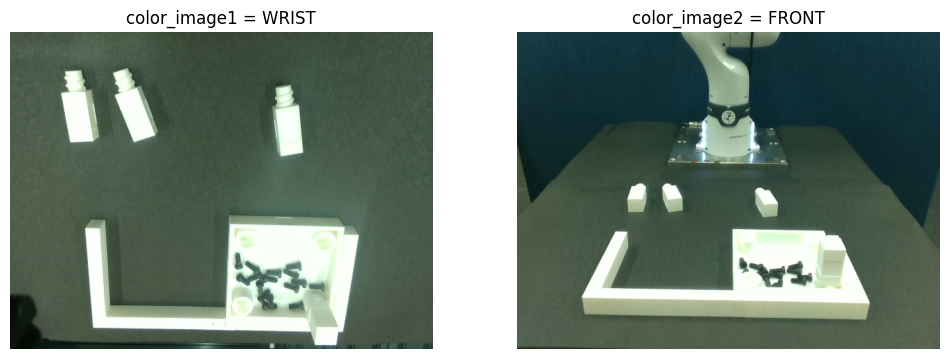

In [9]:
import pyrealsense2 as rs
import matplotlib.pyplot as plt

def grab(serial, w=640, h=480, fps=30, warmup=15):
    cfg = rs.config(); cfg.enable_device(serial)
    cfg.enable_stream(rs.stream.color, w, h, rs.format.rgb8, fps)
    pipe = rs.pipeline(); pipe.start(cfg)
    try:
        for _ in range(warmup): frames = pipe.wait_for_frames()   # 等自动曝光稳定
        return np.asanyarray(frames.get_color_frame().get_data()).copy()
    finally:
        pipe.stop()

wrist, front = grab(WRIST_CAMERA_SERIAL), grab(FRONT_CAMERA_SERIAL)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].imshow(wrist); ax[0].set_title("color_image1 = WRIST"); ax[1].imshow(front); ax[1].set_title("color_image2 = FRONT")
for a in ax: a.axis("off")
plt.show()

如果对应反了,就去改 [serials.py](../src/real/serials.py) 里的两个常量,然后 **重启内核** 再运行本节。

### 构图检查(§7.1,重要)

策略能看到的区域是原图 **x ∈ [96, 544]、y ∈ [16, 464]**。U 形固定条(含 ±2 cm 随机范围)、全部零件、桌腿孔和指尖活动范围,都要落在青色框内并留 20–30 px 余量。

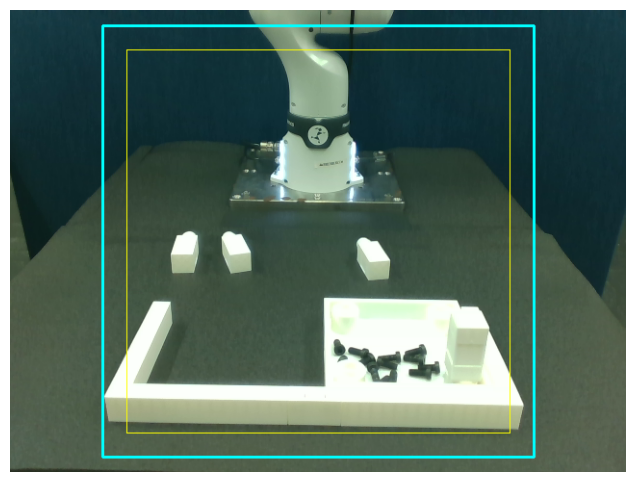

In [10]:
import cv2
vis = front.copy()
cv2.rectangle(vis, (96, 16), (544, 464), (0, 255, 255), 2)
cv2.rectangle(vis, (96+25, 16+25), (544-25, 464-25), (255, 255, 0), 1)   # 留 25px 余量
plt.figure(figsize=(8, 6)); plt.imshow(vis); plt.axis("off"); plt.show()

## 步骤 7.4(1):读内参

读出厂内参,填进 [isaac_lab_rerender.py:136-149](../src/sim2real/isaac_lab_rerender.py#L136-L149) 的 `front_435_camera_matrix` 和 `wrist_435_camera_matrix`。`build_camera_params` 只用 fx、fy 的平均值,cx、cy 没用上。

**运行前关掉其他占用相机的进程**(比如实时预览),不然会报设备忙。

In [11]:
def intrinsics(serial):
    cfg = rs.config(); cfg.enable_device(serial)
    cfg.enable_stream(rs.stream.color, 640, 480, rs.format.rgb8, 30)
    pipe = rs.pipeline(); prof = pipe.start(cfg)
    i = prof.get_stream(rs.stream.color).as_video_stream_profile().get_intrinsics()
    pipe.stop(); return i

for name, s in [("front", FRONT_CAMERA_SERIAL), ("wrist", WRIST_CAMERA_SERIAL)]:
    i = intrinsics(s)
    print(f"{name}_435_camera_matrix = np.array([")
    print(f"    [{i.fx:.8f}, 0.0, {i.ppx:.8f}],\n    [0.0, {i.fy:.8f}, {i.ppy:.8f}],\n    [0.0, 0.0, 1.0],\n])")
    print()

front_435_camera_matrix = np.array([
    [603.70898438, 0.0, 322.38723755],
    [0.0, 603.42315674, 249.26660156],
    [0.0, 0.0, 1.0],
])

wrist_435_camera_matrix = np.array([
    [607.46057129, 0.0, 316.16723633],
    [0.0, 606.96691895, 243.04000854],
    [0.0, 0.0, 1.0],
])



把输出的两个矩阵覆盖进渲染器文件对应位置(目前的值:front fx≈607.25 / wrist fx≈613.15,是作者的相机)。

## 步骤 7.4(2):外参初值

**测量法**(粗略,可先用来渲染看看):用 §4.2 读出相机镜头附近一点的基座系坐标,卷尺量高度,手机水平仪量俯角。
**手眼标定法**(更准):前视用 `cv2.calibrateRobotWorldHandEye`,腕部用 `cv2.calibrateHandEye`,走 15–20 个姿态。这需要另外写采集脚本,见文档。

下面用测量法。填你的前视相机在**基座系**下的位置(米)、俯角和偏航(面朝机器人 = 0°)。默认值是作者的标称位姿。

In [12]:
FLIP = np.diag([1, -1, -1])                        # OpenCV 相机系 → USD 相机系
BASE_TO_WORLD = np.array([-0.30, 0.0, 0.415])      # 世界坐标 = 基座坐标 + 这个

def look_pose(pos, pitch_deg, yaw_deg=0.0):
    """OpenCV 约定(x 右、y 下、z 前)下,相机在基座系的 4x4 位姿。
    yaw=0 面朝 -x(面朝机器人),pitch 为下俯角,无侧倾。"""
    th, ps = np.radians(pitch_deg), np.radians(yaw_deg)
    z = np.array([-np.cos(th)*np.cos(ps), -np.cos(th)*np.sin(ps), -np.sin(th)])
    x = np.cross(z, [0, 0, 1]); x /= np.linalg.norm(x)
    y = np.cross(z, x)
    T = np.eye(4); T[:3, :3] = np.c_[x, y, z]; T[:3, 3] = pos
    return T

# ====== 改这里 ======
FRONT_POS_BASE = [1.13, 0, 0.415]   # 基座系 (x, y, z) 米
FRONT_PITCH    = 35.5                    # 下俯角,度
FRONT_YAW      = 0.0                     # 偏航,度
# ====================
T_base_front = look_pose(FRONT_POS_BASE, FRONT_PITCH, FRONT_YAW)

## 步骤 7.4(3):换算成渲染器格式

渲染器用 Isaac/USD 相机约定:视线沿 −Z,上方向 +Y,内旋 "XYZ" 欧拉角。
先用标称值做**自检**:应得到 `pos=(0.82, -0.065, 0.8)`、`euler=[0, 68.5, 90]`。

In [13]:
def front_to_rerender(T_base_cam):
    pos = T_base_cam[:3, 3] + BASE_TO_WORLD
    eul = R.from_matrix(T_base_cam[:3, :3] @ FLIP).as_euler("XYZ", degrees=True)
    return pos, eul

def wrist_to_rerender(T_flange_cam):
    # panda_hand = 法兰绕 z 转 -45°
    T_hand_flange = np.eye(4); T_hand_flange[:3, :3] = R.from_euler("z", 45, degrees=True).as_matrix()
    T = T_hand_flange @ T_flange_cam
    return T[:3, 3], R.from_matrix(T[:3, :3] @ FLIP).as_euler("XYZ", degrees=True)

# 自检:标称前视
p, e = front_to_rerender(look_pose([1.12, -0.065, 0.385], 21.5))
print("nominal  pos =", np.round(p, 4), " euler =", np.round(e, 2), "  (期望 [0.82 -0.065 0.8], [0 68.5 90])")

# 你的前视
pos, eul = front_to_rerender(T_base_front)
print("\n你的前视 → isaac_lab_rerender.py 里:")
print(f"  cam_pos = np.array({np.round(pos, 4).tolist()})")
print(f"  R.from_euler('XYZ', np.deg2rad({np.round(eul, 2).tolist()}))")

nominal  pos = [ 0.82  -0.065  0.8  ]  euler = [ 0.  68.5 90. ]   (期望 [0.82 -0.065 0.8], [0 68.5 90])

你的前视 → isaac_lab_rerender.py 里:
  cam_pos = np.array([0.83, 0.0, 0.83])
  R.from_euler('XYZ', np.deg2rad([0.0, 54.5, 90.0]))


把输出填进 [isaac_lab_rerender.py:735-741](../src/sim2real/isaac_lab_rerender.py#L735-L741) 的 `cam_pos` 和 `cam_quat`。

**腕部**:标称值已经写在渲染器里(`local_wrist_pos = (-0.05, 0, 0.04)`,`[0, 200, -90]°`),只要你的支架和作者的一致可以先不改。如果支架不同,用手眼标定得到 `T_flange_cam`(4×4,OpenCV 约定),然后:

In [ ]:
# T_flange_cam = ...   # 手眼标定结果,取消注释并填入
# pos_w, eul_w = wrist_to_rerender(T_flange_cam)
# print("local_wrist_pos =", np.round(pos_w, 4).tolist(), " euler XYZ(deg) =", np.round(eul_w, 2).tolist())

## 步骤 7.4(4):叠图对齐(必做)

目标:真实画面和渲染画面在**完全相同的状态**下重合。

### 4.1 选参考状态并截短
把 `SRC_PKL` 指向一个仿真 rollout pickle,例如 `$DATA_DIR_RAW/raw/diffik/sim/one_leg/rollout/low/success/` 下任一个。会写出 `scratch/align/align.pkl`,并打印真机需要复现的**关节角**和**零件位置**。

In [14]:
SRC_PKL = "data/raw/diffik/sim/one_leg/rollout/med/success/2026-10-06T12:46:20.083323.pkl"
(REPO/"scratch"/"make_align_pkl.py").write_text('''
import sys, pickle, numpy as np
from scipy.spatial.transform import Rotation as R
from src.visualization.render_mp4 import unpickle_data
d = unpickle_data(sys.argv[1])
d["observations"] = d["observations"][:3]; d["actions"] = d["actions"][:2]
for k in ("rewards", "skills"):
    if k in d: d[k] = d[k][:2]
pickle.dump(d, open(sys.argv[2], "wb"))
A = np.array([[0,1,0,0.0015],[1,0,0,0],[0,0,-1,0.415],[0,0,0,1.]]); base = np.array([-0.3,0,0.415])
o = d["observations"][0]
print("joints:", np.round(o["robot_state"]["joint_positions"], 4).tolist())
pp = np.asarray(o["parts_poses"]).reshape(-1, 7)
for name, p in zip(["tabletop","leg1","leg2","leg3","leg4","obstacle_front"], pp):
    T = np.eye(4); T[:3, 3] = p[:3]; T[:3, :3] = R.from_quat(p[3:]).as_matrix()
    print(f"{name:15s} (x, y) = ({(A@T)[0,3]*100-base[0]*100:6.1f}, {(A@T)[1,3]*100:6.1f}) cm")
''')
r = subprocess.run([RESIP_PY, "scratch/make_align_pkl.py", SRC_PKL, str(ALIGN/"align.pkl")],
                   capture_output=True, text=True, cwd=REPO, env={**os.environ, "PYTHONPATH": str(REPO)})
print(r.stdout, r.stderr[-1500:])

Importing module 'gym_38' (/home/kaiyuan.luo/isaacgym/python/isaacgym/_bindings/linux-x86_64/gym_38.so)
Setting GYM_USD_PLUG_INFO_PATH to /home/kaiyuan.luo/isaacgym/python/isaacgym/_bindings/linux-x86_64/usd/plugInfo.json
joints: [0.1476999968290329, 0.5077000260353088, -0.004000000189989805, -2.2291998863220215, -0.10830000042915344, 2.3424999713897705, 0.04309999942779541]
tabletop        (x, y) = (  55.8,   -1.0) cm
leg1            (x, y) = (  37.0,  -20.3) cm
leg2            (x, y) = (  37.2,  -12.0) cm
leg3            (x, y) = (  37.2,   12.2) cm
leg4            (x, y) = (  37.1,   20.2) cm
obstacle_front  (x, y) = (  67.6,   -1.3) cm
 


侧挡条跟前挡条一起移动:x 比前挡条小 7.5 cm,y = ±17.5 cm。**把上面打印的 `joints:` 那行抄到下一格。**

### 4.2 真机复现并拍照
1. 在下一格填 `JOINTS`,**手放急停**,运行,机械臂会移到该姿态。
2. 按打印出的坐标摆好零件和挡条(用 §4.1 的标记点)。
3. 再运行拍照格,生成 `real_front.png` 和 `real_wrist.png`。

In [ ]:
import subprocess
# Polymetis 装在 polymetis-local 环境里,而本 notebook 的内核是 resip,所以用子进程调用
POLY_PY = "/home/kaiyuan.luo/miniconda3/envs/polymetis-local/bin/python"
JOINTS = [0.1476999968290329, 0.5077000260353088, -0.004000000189989805, -2.2291998863220215, -0.10830000042915344, 2.3424999713897705, 0.04309999942779541]   # 例如 [0.1477, 0.5077, ...]  ← 从上一格输出抄过来
if JOINTS is None:
    print("先填 JOINTS")
else:
    script = f"""
import torch
from polymetis import RobotInterface
robot = RobotInterface(ip_address="localhost")
robot.move_to_joint_positions(torch.tensor({list(JOINTS)}, dtype=torch.float32), time_to_go=6.0)
print("到位")
"""
    r = subprocess.run([POLY_PY, "-c", script], capture_output=True, text=True)
    print(r.stdout, r.stderr[-1500:])


In [ ]:
# 自包含:内核重启后也能单独运行
import sys, numpy as np, matplotlib.pyplot as plt
import pyrealsense2 as rs
from pathlib import Path
REPO = Path("/home/kaiyuan.luo/ResiP"); sys.path.insert(0, str(REPO))
from src.real.serials import FRONT_CAMERA_SERIAL, WRIST_CAMERA_SERIAL
ALIGN = REPO / "scratch" / "align"; ALIGN.mkdir(parents=True, exist_ok=True)

def grab(serial, w=640, h=480, fps=30, warmup=15):
    cfg = rs.config(); cfg.enable_device(serial)
    cfg.enable_stream(rs.stream.color, w, h, rs.format.rgb8, fps)
    pipe = rs.pipeline(); pipe.start(cfg)
    try:
        for _ in range(warmup): frames = pipe.wait_for_frames()
        return np.asanyarray(frames.get_color_frame().get_data()).copy()
    finally:
        pipe.stop()

wrist, front = grab(WRIST_CAMERA_SERIAL), grab(FRONT_CAMERA_SERIAL)
plt.imsave(str(ALIGN/"real_front.png"), front); plt.imsave(str(ALIGN/"real_wrist.png"), wrist)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5)); ax[0].imshow(front); ax[0].set_title("front"); ax[1].imshow(wrist); ax[1].set_title("wrist")
for a in ax: a.axis("off")
plt.show()
print("saved to", ALIGN)


### 4.3 渲染同一状态(在 Isaac Lab 电脑上手动运行,不加 `-dr`)
本机没有 Isaac Lab,渲染要在另一台电脑上本地运行。**每次改外参后都要重做下面三步。**
1. 运行下面这格,生成 `scratch/to_isaac.tar.gz`(渲染脚本 + `align.pkl`),拷到 Isaac 电脑(U 盘、网盘、`git push/pull` 都行)。
2. 在 Isaac 电脑上解压到仓库根目录,按打印的命令渲染。
3. 把 Isaac 电脑上的 `scratch/align_out/` 拷回本机的 `scratch/` 下。


In [ ]:
import tarfile
OUT = REPO / "scratch" / "align_out"

# 1) 打包要拷到 Isaac 电脑的文件(路径相对仓库根目录)
bundle = REPO / "scratch" / "to_isaac.tar.gz"
with tarfile.open(bundle, "w:gz") as t:
    t.add(REPO/"src/sim2real/isaac_lab_rerender.py", arcname="src/sim2real/isaac_lab_rerender.py")
    t.add(ALIGN/"align.pkl", arcname="scratch/align/align.pkl")
print("已生成:", bundle, f"({bundle.stat().st_size/1e6:.1f} MB)\n")

# 3) 拷回后检查
print("把 Isaac 电脑上的 scratch/align_out 整个文件夹拷回:", OUT)
print("当前已有的输出 pkl:", sorted(glob.glob(str(OUT/"**"/"*.pkl"), recursive=True))[-3:])

**在 Isaac 电脑上运行**(仓库根目录,`to_isaac.tar.gz` 放在那里):

```bash
tar xzf to_isaac.tar.gz
conda activate isaaclab
rm -rf scratch/align_out
python -m src.sim2real.isaac_lab_rerender --headless -i 0 --sub-steps 3 \
  --load-dir scratch/align --furniture one_leg --num-parts 5 \
  --save --save-dir scratch/align_out
```

渲染完,把 Isaac 电脑上整个 `scratch/align_out/` 文件夹拷回本机 `scratch/` 下。


In [ ]:
# 取输出 pickle 的第 0 帧:color_image2 = 前视,color_image1 = 腕部
from src.visualization.render_mp4 import unpickle_data
latest = sorted(glob.glob(str(OUT/"**"/"*.pkl"), recursive=True), key=os.path.getmtime)[-1]
d = unpickle_data(latest); o0 = d["observations"][0]
print("pkl:", latest); print("obs keys:", list(o0.keys()))
sim_front, sim_wrist = np.asarray(o0["color_image2"]), np.asarray(o0["color_image1"])
imageio.imwrite(ALIGN/"sim_front.png", sim_front); imageio.imwrite(ALIGN/"sim_wrist.png", sim_wrist)

### 4.4 叠图
仿真边缘画成**红线**,青色框为策略可见区域。

In [ ]:
def overlay(real_path, sim_path, crop_box=True):
    real, sim = cv2.imread(str(real_path)), cv2.imread(str(sim_path))
    edges = cv2.Canny(cv2.cvtColor(sim, cv2.COLOR_BGR2GRAY), 50, 150)
    out = cv2.addWeighted(real, 0.6, sim, 0.4, 0); out[edges > 0] = (0, 0, 255)
    if crop_box: cv2.rectangle(out, (96, 16), (544, 464), (255, 255, 0), 1)
    return cv2.cvtColor(out, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].imshow(overlay(ALIGN/"real_front.png", ALIGN/"sim_front.png")); ax[0].set_title("FRONT overlay")
ax[1].imshow(overlay(ALIGN/"real_wrist.png", ALIGN/"sim_wrist.png", crop_box=False)); ax[1].set_title("WRIST overlay")
for a in ax: a.axis("off")
plt.show()
cv2.imwrite(str(ALIGN/"overlay_front.png"), cv2.cvtColor(overlay(ALIGN/"real_front.png", ALIGN/"sim_front.png"), cv2.COLOR_RGB2BGR))

### 4.5 调整外参(循环做)
**达标标准**:青框内,桌面边缘、挡条、零件、手指的红线和真实边缘偏差 ≤ **约 5 像素**(0.7 m 处 1° ≈ 10 px)。

**顺序**:
1. 先调**俯仰和偏航**,让整体位置对上;
2. 再调**平移**,让大小和透视对上;
3. 最后调**滚转**。

前视改 `cam_pos`/欧拉角(用步骤 7.4(3) 那格重新算);腕部改 `local_wrist_pos` 和 `local_wrist_rot`。
改完回到 **4.3 → 4.4**,直到达标。

### 4.6 保存基准
把对齐用的 `real_front.png`、`real_wrist.png` 和关节角存好,§9.1 每天开工前检查相机有没有被碰动时会用到。

In [ ]:
import json as _json, shutil
BASE = REPO/"scratch"/"align_baseline"; BASE.mkdir(exist_ok=True)
for f in ["real_front.png", "real_wrist.png", "overlay_front.png"]:
    if (ALIGN/f).exists(): shutil.copy(ALIGN/f, BASE/f)
_json.dump({"joints": JOINTS}, open(BASE/"joints.json", "w"))
print("saved to", BASE)

全部达标后,就可以用你的相机参数跑 Stage 3 的批量渲染了([IMPLEMENTATION_GUIDE.md](../docs/IMPLEMENTATION_GUIDE.md) 3b–3c)。